Multi-timescale Chiarella model simulaiton

In [223]:
import numpy as np
from scipy.optimize import minimize
from scipy.stats import kurtosis
from matplotlib import pyplot as plt
import pandas as pd

In [224]:
params = pd.read_csv("calibrated_alpha_beta.csv")

alpha_k = pd.to_numeric(params["alpha_k"], errors="coerce").to_numpy(dtype=float)
beta_k = pd.to_numeric(params["beta_k"], errors="coerce").to_numpy(dtype=float)

print("alpha_k:", alpha_k)
print("beta_k:", beta_k)
print("n_groups:", len(alpha_k))
print(alpha_k.dtype, beta_k.dtype)

alpha_k: [0.0075329  0.01828065 0.02228814 0.02709265 0.03387841 0.04420053
 0.0658041  0.13642758]
beta_k: [ 0.06315227  0.14877606  0.01942541  0.05206985  0.11281017  0.01576125
 -0.12779127 -0.46021372]
n_groups: 8
float64 float64


In [225]:
def random_x0(seed=None):
    rng = np.random.default_rng(seed)

    kappa0 = np.exp(rng.uniform(np.log(1e-4), np.log(0.5)))
    gamma0 = np.exp(rng.uniform(np.log(1.0), np.log(150.0)))
    sigma_eps0 = np.exp(rng.uniform(np.log(1e-4), np.log(0.3)))
    sigma_eta0 = np.exp(rng.uniform(np.log(1e-4), np.log(0.3)))

    return np.log([kappa0, gamma0, sigma_eps0, sigma_eta0])

In [226]:
def make_random_starts(n_starts=3, seed=None):
    rng = np.random.default_rng(seed)
    starts = []

    for _ in range(n_starts):
        starts.append(random_x0(seed=rng.integers(0, 2**32-1)))

    return starts

In [227]:
def make_shocks_many(T, burnin, n_runs, seed=None):
    rng = np.random.default_rng(seed)
    total_T = T + burnin

    eps_shocks = rng.normal(size=(n_runs, total_T))
    eta_shocks = rng.normal(size=(n_runs, total_T))

    return eps_shocks, eta_shocks

In [228]:
def simulate_model_many(
    T,
    kappa,
    gamma,
    sigma_eps,
    sigma_eta,
    alpha_k,
    beta_k,
    n_runs=1,
    burnin=500,
    seed=None,
    eps_shocks=None,
    eta_shocks=None,
    return_M=False,
):
    rng = np.random.default_rng(seed)

    alpha_k = np.asarray(alpha_k, dtype=float)
    beta_k = np.asarray(beta_k, dtype=float)
    K = len(alpha_k)

    total_T = T + burnin

    p = np.zeros((n_runs, total_T))
    v = np.zeros((n_runs, total_T))
    M = np.zeros((n_runs, K, total_T))

    if eps_shocks is None:
        eps_shocks = rng.normal(size=(n_runs, total_T))
    if eta_shocks is None:
        eta_shocks = rng.normal(size=(n_runs, total_T))

    for t in range(1, total_T):
        if t >= 2:
            r_prev = p[:, t-1] - p[:, t-2]
            M[:, :, t] = (1 - alpha_k)[None, :] * M[:, :, t-1] + alpha_k[None, :] * r_prev[:, None]

        trend = np.sum(beta_k[None, :] * np.tanh(gamma * M[:, :, t]), axis=1)

        eps = sigma_eps * eps_shocks[:, t]
        eta = sigma_eta * eta_shocks[:, t]

        p[:, t] = p[:, t-1] + kappa * (v[:, t-1] - p[:, t-1]) + trend + eps
        v[:, t] = v[:, t-1] + eta

        bad = (
            ~np.isfinite(p[:, t])
            | ~np.isfinite(v[:, t])
            | (np.abs(p[:, t]) > 1e6)
            | (np.abs(v[:, t]) > 1e6)
        )

        if np.any(bad):
            p[bad, t:] = np.nan
            v[bad, t:] = np.nan
            M[bad, :, t:] = np.nan

    p = p[:, burnin:]
    v = v[:, burnin:]
    M = M[:, :, burnin:]

    r = np.diff(p, axis=1)

    if return_M:
        return p, v, r, M

    return p, v, r

Core Moments

In [229]:
def autocorr(x, lag):
    x = np.asarray(x)
    x = x - np.mean(x)

    if len(x) <= lag:
        return np.nan

    denom = np.dot(x, x)
    if denom == 0:
        return 0.0

    return np.dot(x[:-lag], x[lag:]) / denom


def variance_ratio_from_prices(p, q=20):
    p = np.asarray(p)
    r1 = np.diff(p)

    rq = p[q:] - p[:-q]

    var1 = np.var(r1)
    varq = np.var(rq)

    if var1 == 0:
        return np.nan

    return varq / (q * var1)


def moments_from_returns_and_prices(r, p):
    r = np.asarray(r)

    return np.array([
        np.std(r),
        kurtosis(r, fisher=True, bias=False),
        autocorr(r, 1),
        autocorr(r**2, 1),
        autocorr(r**2, 5),
        variance_ratio_from_prices(p, q=20),
        variance_ratio_from_prices(p, q=60),
    ])

In [230]:
def make_identity_weight(data_moments):
    return np.eye(len(data_moments))


def make_diagonal_weight(data_moments, floor=1e-3):
    scale = np.maximum(np.abs(data_moments), floor)
    return np.diag(1.0 / scale**2)


def make_covariance_weight(moment_runs, rcond=1e-10, ridge=0.0, verbose=True):
    """
    Computes W = pinv(Cov(moment_runs)).
    Uses optional ridge regularization if needed.
    """
    V = np.cov(moment_runs.T)

    if ridge > 0:
        V = V + ridge * np.eye(V.shape[0])

    eigvals = np.linalg.eigvalsh(V)
    cond = np.linalg.cond(V)

    if verbose:
        print("eigvals V:", eigvals)
        print("condition number:", cond)

    W = np.linalg.pinv(V, rcond=rcond)

    return W

GMM objective

In [231]:
def simulate_moments_average_many_from_shocks(
    theta,
    alpha_k,
    beta_k,
    T,
    shocks,
    burnin=500,
):
    kappa, gamma, sigma_eps, sigma_eta = theta
    eps_shocks, eta_shocks = shocks
    n_runs = eps_shocks.shape[0]

    p_many, v_many, r_many = simulate_model_many(
        T=T,
        kappa=kappa,
        gamma=gamma,
        sigma_eps=sigma_eps,
        sigma_eta=sigma_eta,
        alpha_k=alpha_k,
        beta_k=beta_k,
        n_runs=n_runs,
        burnin=burnin,
        eps_shocks=eps_shocks,
        eta_shocks=eta_shocks,
    )

    moment_runs = np.array([
        moments_from_returns_and_prices(r_many[i], p_many[i])
        for i in range(n_runs)
    ])

    return np.nanmean(moment_runs, axis=0), moment_runs


def gmm_objective(
    theta_raw,
    data_moments,
    W,
    alpha_k,
    beta_k,
    T,
    shocks,
):
    theta_raw = np.asarray(theta_raw, dtype=float)

    # If optimizer proposes impossible values
    if not np.all(np.isfinite(theta_raw)):
        return 1e12

    theta = np.exp(theta_raw)

    kappa, gamma, sigma_eps, sigma_eta = theta

    # Extra safety bounds
    if not (
        1e-4 <= kappa <= 0.5
        and 1.0 <= gamma <= 150.0
        and 1e-4 <= sigma_eps <= 0.3
        and 1e-4 <= sigma_eta <= 0.3
    ):
        return 1e12

    try:
        sim_moments, _ = simulate_moments_average_many_from_shocks(
            theta,
            alpha_k,
            beta_k,
            T,
            shocks,
        )

        if not np.all(np.isfinite(sim_moments)):
            return 1e12

        diff = sim_moments - data_moments

        if not np.all(np.isfinite(diff)):
            return 1e12

        value = diff @ W @ diff

        if not np.isfinite(value):
            return 1e12

        return value

    except Exception:
        return 1e12

Optimization

In [232]:
def estimate_gmm(
    data_moments,
    alpha_k,
    beta_k,
    T,
    W,
    shocks,
    x0=None,
    method="Powell",
):
    if x0 is None:
        x0 = random_x0(seed=None)

    bounds_raw = [
        (np.log(1e-4), np.log(0.5)),    # kappa
        (np.log(1.0),  np.log(150.0)),  # gamma
        (np.log(1e-4), np.log(0.3)),    # sigma_eps
        (np.log(1e-4), np.log(0.3)),    # sigma_eta
    ]

    if method == "L-BFGS-B":
        options = {
            "maxiter": 300,
            "ftol": 1e-6,
            "gtol": 1e-4,
        }
    elif method == "Powell":
        options = {
            "maxiter": 300,
            "xtol": 1e-4,
            "ftol": 1e-6,
        }
    else:
        options = {
            "maxiter": 300,
        }

    res = minimize(
        gmm_objective,
        x0=x0,
        args=(data_moments, W, alpha_k, beta_k, T, shocks),
        method=method,
        bounds=bounds_raw,
        options=options,
    )

    theta_hat = np.exp(res.x)

    return theta_hat, res

Iterative optimal GMM

In [233]:
def fixed_weight_gmm_from_start(
    data_moments,
    alpha_k,
    beta_k,
    T,
    W,
    shocks_obj,
    x0,
    method="Powell",
):
    theta_hat, res = estimate_gmm(
        data_moments=data_moments,
        alpha_k=alpha_k,
        beta_k=beta_k,
        T=T,
        W=W,
        shocks=shocks_obj,
        x0=x0,
        method=method,
    )

    return theta_hat, res

In [234]:
def optimal_gmm_from_start(
    data_moments,
    alpha_k,
    beta_k,
    T,
    x0,
    n_runs_obj=20,
    n_runs_cov=200,
    seed=None,
    n_iter=3,
    method="Powell",
    rcond=1e-10,
    ridge=0.0,
):
    rng = np.random.default_rng(seed)

    W = make_identity_weight(data_moments)
    theta_current = None
    res_current = None
    history = []

    current_x0 = x0

    for it in range(n_iter):
        shocks_obj = make_shocks_many(
            T=T,
            burnin=500,
            n_runs=n_runs_obj,
            seed=int(rng.integers(0, 2**32 - 1)),
        )

        theta_hat, res = estimate_gmm(
            data_moments=data_moments,
            alpha_k=alpha_k,
            beta_k=beta_k,
            T=T,
            W=W,
            shocks=shocks_obj,
            x0=current_x0,
            method=method,
        )

        theta_current = theta_hat
        res_current = res

        history.append({
            "iter": it,
            "theta": theta_hat,
            "objective": res.fun,
            "success": res.success,
            "message": res.message,
            "nit": res.nit,
        })

        print(f"Iter {it}: theta = {theta_hat}, objective = {res.fun:.4g}, success = {res.success}")

        # Do not update W after the final iteration
        if it < n_iter - 1:
            shocks_cov = make_shocks_many(
                T=T,
                burnin=500,
                n_runs=n_runs_cov,
                seed=int(rng.integers(0, 2**32 - 1)),
            )

            _, moment_runs = simulate_moments_average_many_from_shocks(
                theta_hat,
                alpha_k,
                beta_k,
                T,
                shocks_cov,
            )

            W = make_covariance_weight(
                moment_runs,
                rcond=rcond,
                ridge=ridge,
                verbose=True,
            )

            current_x0 = np.log(theta_hat)

    return theta_current, res_current, W, history

In [235]:
def evaluate_theta_with_fixed_W(
    theta,
    data_moments,
    alpha_k,
    beta_k,
    T,
    W_eval,
    shocks_eval,
):
    return gmm_objective(
        np.log(theta),
        data_moments,
        W_eval,
        alpha_k,
        beta_k,
        T,
        shocks_eval,
    )

In [236]:
def compare_gmm_methods_multistart(
    data_moments,
    alpha_k,
    beta_k,
    T,
    starts,
    n_runs_obj=20,
    n_runs_cov=200,
    seed=123,
    method="Powell",
):
    rng = np.random.default_rng(seed)

    W_identity = make_identity_weight(data_moments)
    W_diag = make_diagonal_weight(data_moments)

    shocks_obj_shared = make_shocks_many(
        T=T,
        burnin=500,
        n_runs=n_runs_obj,
        seed=int(rng.integers(0, 2**32 - 1)),
    )

    shocks_eval = make_shocks_many(
        T=T,
        burnin=500,
        n_runs=n_runs_obj,
        seed=int(rng.integers(0, 2**32 - 1)),
    )

    W_eval = W_identity

    all_results = []

    for start_id, x0 in enumerate(starts):
        theta0 = np.exp(x0)

        # 1. Identity GMM
        theta_id, res_id = fixed_weight_gmm_from_start(
            data_moments=data_moments,
            alpha_k=alpha_k,
            beta_k=beta_k,
            T=T,
            W=W_identity,
            shocks_obj=shocks_obj_shared,
            x0=x0,
            method=method,
        )

        score_id = evaluate_theta_with_fixed_W(
            theta_id, data_moments, alpha_k, beta_k, T, W_eval, shocks_eval
        )

        all_results.append({
            "method": "identity",
            "start_id": start_id,
            "theta0": theta0,
            "theta_hat": theta_id,
            "train_objective": res_id.fun,
            "eval_score": score_id,
            "success": res_id.success,
            "nit": res_id.nit,
            "message": res_id.message,
        })

        # 2. Diagonal GMM
        theta_diag, res_diag = fixed_weight_gmm_from_start(
            data_moments=data_moments,
            alpha_k=alpha_k,
            beta_k=beta_k,
            T=T,
            W=W_diag,
            shocks_obj=shocks_obj_shared,
            x0=x0,
            method=method,
        )

        score_diag = evaluate_theta_with_fixed_W(
            theta_diag, data_moments, alpha_k, beta_k, T, W_eval, shocks_eval
        )

        all_results.append({
            "method": "diagonal",
            "start_id": start_id,
            "theta0": theta0,
            "theta_hat": theta_diag,
            "train_objective": res_diag.fun,
            "eval_score": score_diag,
            "success": res_diag.success,
            "nit": res_diag.nit,
            "message": res_diag.message,
        })

        # 3. Optimal GMM
        theta_opt, res_opt, W_opt, hist_opt = optimal_gmm_from_start(
            data_moments=data_moments,
            alpha_k=alpha_k,
            beta_k=beta_k,
            T=T,
            x0=x0,
            n_runs_obj=n_runs_obj,
            n_runs_cov=n_runs_cov,
            seed=int(rng.integers(0, 2**32 - 1)),
            n_iter=3,
            method=method,
            rcond=1e-10,
            ridge=0.0,
        )

        score_opt = evaluate_theta_with_fixed_W(
            theta_opt, data_moments, alpha_k, beta_k, T, W_eval, shocks_eval
        )

        all_results.append({
            "method": "optimal_pinv",
            "start_id": start_id,
            "theta0": theta0,
            "theta_hat": theta_opt,
            "train_objective": res_opt.fun,
            "eval_score": score_opt,
            "success": res_opt.success,
            "nit": res_opt.nit,
            "message": res_opt.message,
            "history": hist_opt,
        })

    return all_results

In [237]:
theta_true = np.array([
    0.015, # kappa
    36.7, # gamma
    0.043, # sigma_eps
    0.018, # sigma_eta
], dtype=float)

param_names = ["kappa", "gamma", "sigma_eps", "sigma_eta"]

In [238]:
starts = make_random_starts(n_starts=3, seed=42)

In [239]:
T = 2000

p_many, v_many, r_many = simulate_model_many(
    T=T,
    kappa=theta_true[0],
    gamma=theta_true[1],
    sigma_eps=theta_true[2],
    sigma_eta=theta_true[3],
    alpha_k=alpha_k,
    beta_k=beta_k,
    n_runs=1,
    seed=42,
)

p = p_many[0]
r = r_many[0]

data_moments = moments_from_returns_and_prices(r, p)

In [240]:
all_results = compare_gmm_methods_multistart(
    data_moments=data_moments,
    alpha_k=alpha_k,
    beta_k=beta_k,
    T=T,
    starts=starts,
    n_runs_obj=20,
    n_runs_cov=200,
    seed=123,
    method="Powell",
)

Iter 0: theta = [4.98325525e-01 2.71097133e+01 3.87838272e-02 9.66075197e-03], objective = 0.04981, success = True
eigvals V: [2.41157379e-08 4.88243299e-08 5.55218239e-07 7.60115631e-06
 3.61485022e-05 2.85682577e-04 2.34625862e-03]
condition number: 97291.59555507469
Iter 1: theta = [3.37300202e-02 3.59610252e+01 4.31318377e-02 1.70688510e-02], objective = 14.93, success = True
eigvals V: [1.61232581e-07 3.91628354e-07 2.41236145e-06 5.59285877e-06
 6.99332813e-05 5.10182668e-04 1.61459754e-03]
condition number: 10014.089712707048
Iter 2: theta = [7.69095056e-03 3.71096748e+01 4.26034114e-02 1.37466405e-02], objective = 5.612, success = True
Iter 0: theta = [3.20948305e-04 3.71981789e+01 3.56152545e-02 2.88863823e-01], objective = 0.007894, success = True
eigvals V: [8.89718051e-08 1.07257512e-07 2.79517008e-06 4.94838862e-06
 1.88974017e-04 6.39129479e-04 2.21954913e-03]
condition number: 24946.657290946256
Iter 1: theta = [1.10020124e-03 3.68130338e+01 4.39337465e-02 1.38383113e-02

In [241]:
rows = []

for r in all_results:
    theta_hat = r["theta_hat"]
    
    row = {
        "method": r["method"],
        "start_id": r["start_id"],
        "train_objective": r["train_objective"],
        "eval_score": r["eval_score"],
        "success": r["success"],
        "nit": r["nit"],
        "kappa_hat": theta_hat[0],
        "gamma_hat": theta_hat[1],
        "sigma_eps_hat": theta_hat[2],
        "sigma_eta_hat": theta_hat[3],
    }
    
    rows.append(row)

results_df = pd.DataFrame(rows)

results_df.sort_values("eval_score")

,method,start_id,train_objective,eval_score,success,nit,kappa_hat,gamma_hat,sigma_eps_hat,sigma_eta_hat
3,identity,1,0.003566,0.003037,True,7,0.000112,38.464282,0.045235,0.016695
2,optimal_pinv,0,5.612494,0.004443,True,8,0.007691,37.109675,0.042603,0.013747
8,optimal_pinv,2,5.016438,0.005595,True,7,0.002093,37.325246,0.042671,0.028451
5,optimal_pinv,1,8.745235,0.005842,True,6,0.002478,37.295678,0.043256,0.003402
0,identity,0,0.053998,0.045800,True,2,0.496643,27.184200,0.041824,0.006305
1,diagonal,0,6.638156,0.315900,True,3,0.002781,56.704346,0.010581,0.004349
6,identity,2,0.374506,0.374976,True,2,0.000316,55.811123,0.005721,0.064047
4,diagonal,1,2.756540,0.496555,True,2,0.001230,46.956843,0.005859,0.016973
7,diagonal,2,8.355562,3.060013,True,2,0.001590,25.583896,0.002353,0.002432


In [242]:
param_names = ["kappa", "gamma", "sigma_eps", "sigma_eta"]

for i, name in enumerate(param_names):
    results_df[f"{name}_rel_error_%"] = 100 * (
        results_df[f"{name}_hat"] - theta_true[i]
    ) / theta_true[i]

    results_df[f"{name}_log_error"] = np.log(
        results_df[f"{name}_hat"] / theta_true[i]
    )

results_df["mean_abs_log_error"] = results_df[
    [f"{name}_log_error" for name in param_names]
].abs().mean(axis=1)

results_df.sort_values("mean_abs_log_error")

,method,start_id,train_objective,eval_score,success,nit,kappa_hat,gamma_hat,sigma_eps_hat,sigma_eta_hat,kappa_rel_error_%,kappa_log_error,gamma_rel_error_%,gamma_log_error,sigma_eps_rel_error_%,sigma_eps_log_error,sigma_eta_rel_error_%,sigma_eta_log_error,mean_abs_log_error
2,optimal_pinv,0,5.612494,0.004443,True,8,0.007691,37.109675,0.042603,0.013747,-48.726996,-0.668006,1.116280,0.011101,-0.922299,-0.009266,-23.629775,-0.269577,0.239487
8,optimal_pinv,2,5.016438,0.005595,True,7,0.002093,37.325246,0.042671,0.028451,-86.044810,-1.969319,1.703667,0.016893,-0.765611,-0.007686,58.058980,0.457798,0.612924
5,optimal_pinv,1,8.745235,0.005842,True,6,0.002478,37.295678,0.043256,0.003402,-83.482310,-1.800738,1.623100,0.016101,0.596073,0.005943,-81.098644,-1.665937,0.872180
4,diagonal,1,2.756540,0.496555,True,2,0.001230,46.956843,0.005859,0.016973,-91.800080,-2.501046,27.947800,0.246452,-86.375375,-1.993291,-5.708137,-0.058775,1.199891
0,identity,0,0.053998,0.045800,True,2,0.496643,27.184200,0.041824,0.006305,3210.953314,3.499821,-25.928610,-0.300141,-2.735983,-0.027741,-64.969561,-1.048953,1.219164
1,diagonal,0,6.638156,0.315900,True,3,0.002781,56.704346,0.010581,0.004349,-81.457448,-1.685102,54.507755,0.435074,-75.392750,-1.402129,-75.837970,-1.420388,1.235673
3,identity,1,0.003566,0.003037,True,7,0.000112,38.464282,0.045235,0.016695,-99.255021,-4.899569,4.807308,0.046953,5.197290,0.050667,-7.252074,-0.075285,1.268119
7,diagonal,2,8.355562,3.060013,True,2,0.001590,25.583896,0.002353,0.002432,-89.401371,-2.244446,-30.289112,-0.360814,-94.528499,-2.905617,-86.488468,-2.001627,1.878126
6,identity,2,0.374506,0.374976,True,2,0.000316,55.811123,0.005721,0.064047,-97.892152,-3.859503,52.073904,0.419196,-86.694254,-2.016974,255.817234,1.269247,1.891230


In [243]:
summary_by_method = (
    results_df
    .groupby("method")
    .agg(
        best_eval_score=("eval_score", "min"),
        mean_eval_score=("eval_score", "mean"),
        best_mean_abs_log_error=("mean_abs_log_error", "min"),
        mean_abs_log_error=("mean_abs_log_error", "mean"),
        success_rate=("success", "mean"),
    )
    .sort_values("best_mean_abs_log_error")
)

summary_by_method

,best_eval_score,mean_eval_score,best_mean_abs_log_error,mean_abs_log_error,success_rate
method,,,,,
optimal_pinv,0.004443,0.005293,0.239487,0.574864,1.0
diagonal,0.315900,1.290823,1.199891,1.437897,1.0
identity,0.003037,0.141271,1.219164,1.459504,1.0


In [244]:
best_by_method = (
    results_df
    .sort_values("mean_abs_log_error")
    .groupby("method")
    .head(1)
    .sort_values("mean_abs_log_error")
)

best_by_method[
    [
        "method",
        "start_id",
        "eval_score",
        "train_objective",
        "mean_abs_log_error",
        "kappa_hat",
        "gamma_hat",
        "sigma_eps_hat",
        "sigma_eta_hat",
        "kappa_rel_error_%",
        "gamma_rel_error_%",
        "sigma_eps_rel_error_%",
        "sigma_eta_rel_error_%",
    ]
]

,method,start_id,eval_score,train_objective,mean_abs_log_error,kappa_hat,gamma_hat,sigma_eps_hat,sigma_eta_hat,kappa_rel_error_%,gamma_rel_error_%,sigma_eps_rel_error_%,sigma_eta_rel_error_%
2,optimal_pinv,0,0.004443,5.612494,0.239487,0.007691,37.109675,0.042603,0.013747,-48.726996,1.11628,-0.922299,-23.629775
4,diagonal,1,0.496555,2.756540,1.199891,0.001230,46.956843,0.005859,0.016973,-91.800080,27.94780,-86.375375,-5.708137
0,identity,0,0.045800,0.053998,1.219164,0.496643,27.184200,0.041824,0.006305,3210.953314,-25.92861,-2.735983,-64.969561


In [245]:
def recovery_compare_methods(
    theta_true,
    alpha_k,
    beta_k,
    T,
    n_experiments=5,
    n_starts=3,
    n_runs_obj=20,
    n_runs_cov=200,
    base_seed=123,
    method="Powell",
):
    all_rows = []

    rng = np.random.default_rng(base_seed)

    for exp_id in range(n_experiments):
        print(f"\n===== Experiment {exp_id + 1}/{n_experiments} =====")

        # Different synthetic data seed for each experiment
        data_seed = int(rng.integers(0, 2**32 - 1))
        starts_seed = int(rng.integers(0, 2**32 - 1))
        gmm_seed = int(rng.integers(0, 2**32 - 1))

        # 1. Generate one synthetic dataset
        p_many, v_many, r_many = simulate_model_many(
            T=T,
            kappa=theta_true[0],
            gamma=theta_true[1],
            sigma_eps=theta_true[2],
            sigma_eta=theta_true[3],
            alpha_k=alpha_k,
            beta_k=beta_k,
            n_runs=1,
            seed=data_seed,
        )

        p = p_many[0]
        r = r_many[0]

        data_moments = moments_from_returns_and_prices(r, p)

        # 2. Generate random starts for this experiment
        starts = make_random_starts(
            n_starts=n_starts,
            seed=starts_seed,
        )

        # 3. Run method comparison
        results = compare_gmm_methods_multistart(
            data_moments=data_moments,
            alpha_k=alpha_k,
            beta_k=beta_k,
            T=T,
            starts=starts,
            n_runs_obj=n_runs_obj,
            n_runs_cov=n_runs_cov,
            seed=gmm_seed,
            method=method,
        )

        # 4. Store results
        for rdict in results:
            theta_hat = rdict["theta_hat"]

            row = {
                "exp_id": exp_id,
                "method": rdict["method"],
                "start_id": rdict["start_id"],
                "train_objective": rdict["train_objective"],
                "eval_score": rdict["eval_score"],
                "success": rdict["success"],
                "nit": rdict["nit"],
                "kappa_hat": theta_hat[0],
                "gamma_hat": theta_hat[1],
                "sigma_eps_hat": theta_hat[2],
                "sigma_eta_hat": theta_hat[3],
            }

            all_rows.append(row)

    results_df = pd.DataFrame(all_rows)

    param_names = ["kappa", "gamma", "sigma_eps", "sigma_eta"]

    for i, name in enumerate(param_names):
        results_df[f"{name}_rel_error_%"] = 100 * (
            results_df[f"{name}_hat"] - theta_true[i]
        ) / theta_true[i]

        results_df[f"{name}_log_error"] = np.log(
            results_df[f"{name}_hat"] / theta_true[i]
        )

    results_df["mean_abs_log_error"] = results_df[
        [f"{name}_log_error" for name in param_names]
    ].abs().mean(axis=1)

    return results_df

In [246]:
results_df = recovery_compare_methods(
    theta_true=theta_true,
    alpha_k=alpha_k,
    beta_k=beta_k,
    T=2000,
    n_experiments=5,
    n_starts=3,
    n_runs_obj=20,
    n_runs_cov=200,
    base_seed=123,
    method="Powell",
)


===== Experiment 1/5 =====
Iter 0: theta = [4.88887260e-01 2.66457154e+01 3.60703291e-02 2.78557106e-03], objective = 0.02013, success = True
eigvals V: [2.80902523e-08 5.13910156e-08 5.81890295e-07 7.94944911e-06
 3.07591641e-05 3.51207742e-04 2.29026326e-03]
condition number: 81532.31360249175
Iter 1: theta = [7.35670207e-02 3.60564476e+01 4.42354679e-02 7.00078597e-04], objective = 26.46, success = True
eigvals V: [1.01617353e-07 1.58479391e-07 1.58462864e-06 4.64842610e-06
 6.57263316e-05 4.64112972e-04 1.78963287e-03]
condition number: 17611.488680761177
Iter 2: theta = [2.40926637e-02 3.69382938e+01 4.32022466e-02 9.97724628e-04], objective = 11.47, success = True
Iter 0: theta = [1.33835658e-01 4.85926011e+01 5.44048525e-04 9.15001009e-04], objective = 0.2243, success = True
eigvals V: [3.20422485e-11 1.01107793e-10 1.96483117e-09 8.68998339e-09
 1.29884273e-06 6.24986418e-06 2.57787011e-03]
condition number: 80452222.61408092
Iter 1: theta = [6.62433581e-03 4.85600041e+01 9.47

In [247]:
best_per_experiment = (
    results_df
    .sort_values("mean_abs_log_error")
    .groupby(["exp_id", "method"])
    .head(1)
)

summary_methods = (
    best_per_experiment
    .groupby("method")
    .agg(
        mean_abs_log_error=("mean_abs_log_error", "mean"),
        median_abs_log_error=("mean_abs_log_error", "median"),
        mean_eval_score=("eval_score", "mean"),
        success_rate=("success", "mean"),
        mean_kappa_rel_error=("kappa_rel_error_%", "mean"),
        mean_gamma_rel_error=("gamma_rel_error_%", "mean"),
        mean_sigma_eps_rel_error=("sigma_eps_rel_error_%", "mean"),
        mean_sigma_eta_rel_error=("sigma_eta_rel_error_%", "mean"),
    )
    .sort_values("mean_abs_log_error")
)

summary_methods

,mean_abs_log_error,median_abs_log_error,mean_eval_score,success_rate,mean_kappa_rel_error,mean_gamma_rel_error,mean_sigma_eps_rel_error,mean_sigma_eta_rel_error
method,,,,,,,,
optimal_pinv,0.603643,0.809934,0.052399,1.0,-6.868716,8.809101,-13.033735,-44.869777
identity,0.625992,0.668227,0.036060,1.0,351.349118,7.888213,-2.148565,42.870586
diagonal,1.166937,1.360201,0.781168,1.0,437.272018,-15.421077,-59.727056,-19.306484


In [248]:
param_names = ["kappa", "gamma", "sigma_eps", "sigma_eta"]

# Best run for each method in each experiment
best_per_exp_method = (
    results_df
    .sort_values("mean_abs_log_error")  # synthetic case: choose closest to true theta
    .groupby(["exp_id", "method"])
    .head(1)
)

# Average theta_hat by method
avg_theta_by_method = (
    best_per_exp_method
    .groupby("method")
    .agg(
        avg_kappa_hat=("kappa_hat", "mean"),
        avg_gamma_hat=("gamma_hat", "mean"),
        avg_sigma_eps_hat=("sigma_eps_hat", "mean"),
        avg_sigma_eta_hat=("sigma_eta_hat", "mean"),
        std_kappa_hat=("kappa_hat", "std"),
        std_gamma_hat=("gamma_hat", "std"),
        std_sigma_eps_hat=("sigma_eps_hat", "std"),
        std_sigma_eta_hat=("sigma_eta_hat", "std"),
    )
)

# Add percentage errors
theta_true_dict = {
    "kappa": theta_true[0],
    "gamma": theta_true[1],
    "sigma_eps": theta_true[2],
    "sigma_eta": theta_true[3],
}

for name in param_names:
    avg_theta_by_method[f"{name}_true"] = theta_true_dict[name]
    avg_theta_by_method[f"{name}_error_%"] = (
        100
        * (avg_theta_by_method[f"avg_{name}_hat"] - theta_true_dict[name])
        / theta_true_dict[name]
    )

# Reorder columns
cols = []
for name in param_names:
    cols += [
        f"{name}_true",
        f"avg_{name}_hat",
        f"{name}_error_%",
        f"std_{name}_hat",
    ]

avg_theta_by_method = avg_theta_by_method[cols]

avg_theta_by_method

,kappa_true,avg_kappa_hat,kappa_error_%,std_kappa_hat,gamma_true,avg_gamma_hat,gamma_error_%,std_gamma_hat,sigma_eps_true,avg_sigma_eps_hat,sigma_eps_error_%,std_sigma_eps_hat,sigma_eta_true,avg_sigma_eta_hat,sigma_eta_error_%,std_sigma_eta_hat
method,,,,,,,,,,,,,,,,
diagonal,0.015,0.080591,437.272018,0.072869,36.7,31.040465,-15.421077,11.799787,0.043,0.017317,-59.727056,0.018230,0.018,0.014525,-19.306484,0.008922
identity,0.015,0.067702,351.349118,0.061554,36.7,39.594974,7.888213,6.945334,0.043,0.042076,-2.148565,0.007472,0.018,0.025717,42.870586,0.022428
optimal_pinv,0.015,0.013970,-6.868716,0.006762,36.7,39.932940,8.809101,6.204633,0.043,0.037395,-13.033735,0.011346,0.018,0.009923,-44.869777,0.013104


In [249]:
def recovery_optimal_pinv(
    theta_true,
    alpha_k,
    beta_k,
    T,
    n_experiments=20,
    n_starts=3,
    n_runs_obj=20,
    n_runs_cov=200,
    base_seed=123,
    method="Powell",
    n_iter=3,
    rcond=1e-10,
    ridge=0.0,
):
    all_rows = []
    rng = np.random.default_rng(base_seed)

    for exp_id in range(n_experiments):
        print(f"\n===== Experiment {exp_id + 1}/{n_experiments} =====")

        data_seed = int(rng.integers(0, 2**32 - 1))
        starts_seed = int(rng.integers(0, 2**32 - 1))

        # Synthetic dataset
        p_many, v_many, r_many = simulate_model_many(
            T=T,
            kappa=theta_true[0],
            gamma=theta_true[1],
            sigma_eps=theta_true[2],
            sigma_eta=theta_true[3],
            alpha_k=alpha_k,
            beta_k=beta_k,
            n_runs=1,
            seed=data_seed,
        )

        p = p_many[0]
        r = r_many[0]
        data_moments = moments_from_returns_and_prices(r, p)

        # Random starts
        starts = make_random_starts(
            n_starts=n_starts,
            seed=starts_seed,
        )

        best_theta = None
        best_score = np.inf
        best_res = None
        best_start_id = None

        # Common evaluation shocks for fair comparison across starts
        shocks_eval = make_shocks_many(
            T=T,
            burnin=500,
            n_runs=n_runs_obj,
            seed=int(rng.integers(0, 2**32 - 1)),
        )
        W_eval = np.eye(len(data_moments))

        for start_id, x0 in enumerate(starts):
            run_seed = int(rng.integers(0, 2**32 - 1))

            theta_hat, res, W_final, history = optimal_gmm_from_start(
                data_moments=data_moments,
                alpha_k=alpha_k,
                beta_k=beta_k,
                T=T,
                x0=x0,
                n_runs_obj=n_runs_obj,
                n_runs_cov=n_runs_cov,
                seed=run_seed,
                n_iter=n_iter,
                method=method,
                rcond=rcond,
                ridge=ridge,
            )

            # Since synthetic, you may select by eval score or by GMM objective.
            # For real data, use eval_score / objective, not true error.
            eval_score = evaluate_theta_with_fixed_W(
                theta_hat,
                data_moments,
                alpha_k,
                beta_k,
                T,
                W_eval,
                shocks_eval,
            )

            if eval_score < best_score:
                best_score = eval_score
                best_theta = theta_hat
                best_res = res
                best_start_id = start_id

        row = {
            "exp_id": exp_id,
            "start_id": best_start_id,
            "eval_score": best_score,
            "train_objective": best_res.fun,
            "success": best_res.success,
            "nit": best_res.nit,
            "kappa_hat": best_theta[0],
            "gamma_hat": best_theta[1],
            "sigma_eps_hat": best_theta[2],
            "sigma_eta_hat": best_theta[3],
        }

        all_rows.append(row)

    results = pd.DataFrame(all_rows)

    param_names = ["kappa", "gamma", "sigma_eps", "sigma_eta"]

    for i, name in enumerate(param_names):
        results[f"{name}_rel_error_%"] = 100 * (
            results[f"{name}_hat"] - theta_true[i]
        ) / theta_true[i]

        results[f"{name}_log_error"] = np.log(
            results[f"{name}_hat"] / theta_true[i]
        )

    results["mean_abs_log_error"] = results[
        [f"{name}_log_error" for name in param_names]
    ].abs().mean(axis=1)

    return results

In [250]:
results_optimal_20 = recovery_optimal_pinv(
    theta_true=theta_true,
    alpha_k=alpha_k,
    beta_k=beta_k,
    T=2000,
    n_experiments=20,
    n_starts=3,
    n_runs_obj=20,
    n_runs_cov=200,
    base_seed=123,
    method="Powell",
    n_iter=3,
    rcond=1e-10,
    ridge=0.0,
)


===== Experiment 1/20 =====
Iter 0: theta = [5.00000000e-01 2.65040420e+01 3.70059550e-02 2.41488089e-03], objective = 0.02061, success = True
eigvals V: [3.47628951e-08 7.11805669e-08 5.87050124e-07 9.70806546e-06
 3.07637715e-05 2.54559986e-04 2.78354883e-03]
condition number: 80072.41130207959
Iter 1: theta = [4.46944081e-01 2.68570621e+01 4.14308403e-02 1.33813103e-02], objective = 373.5, success = True
eigvals V: [1.34167405e-07 2.99139304e-07 2.05733628e-06 8.75856791e-06
 2.81932065e-05 6.80615878e-04 2.50292957e-03]
condition number: 18655.273041599812
Iter 2: theta = [3.94305559e-01 2.69104610e+01 3.06360154e-03 1.53629789e-02], objective = 953.1, success = True
Iter 0: theta = [5.97886319e-03 4.21802666e+01 3.85198568e-02 9.22103343e-03], objective = 0.01607, success = True
eigvals V: [1.66531945e-07 3.44645267e-07 3.19015965e-06 1.02532019e-05
 2.05570274e-04 5.35422703e-04 1.42328640e-03]
condition number: 8546.626846497413
Iter 1: theta = [3.52493635e-03 3.76975855e+01 4.

In [252]:
results_optimal_20.to_csv("recovery_optimal_GMM_20.csv", index=False)

In [ ]:
param_names = ["kappa", "gamma", "sigma_eps", "sigma_eta"]
hat_cols = [f"{name}_hat" for name in param_names]

estimates = results_optimal_20[hat_cols].to_numpy()

bias = estimates.mean(axis=0) - theta_true
std = estimates.std(axis=0)
rmse = np.sqrt(np.mean((estimates - theta_true) ** 2, axis=0))
rel_rmse = np.sqrt(np.mean(((estimates - theta_true) / theta_true) ** 2, axis=0))
log_rmse = np.sqrt(np.mean((np.log(estimates / theta_true)) ** 2, axis=0))

summary_optimal_20 = pd.DataFrame({
    "true": theta_true,
    "mean_est": estimates.mean(axis=0),
    "bias": bias,
    "std": std,
    "rmse": rmse,
    "rel_rmse_%": 100 * rel_rmse,
    "log_rmse": log_rmse,
}, index=param_names)

summary_optimal_20

,true,mean_est,bias,std,rmse,rel_rmse_%,log_rmse
kappa,0.015,0.019073,0.004073,0.022381,0.022748,151.654681,2.223416
gamma,36.700,36.692569,-0.007431,0.799064,0.799098,2.177379,0.021952
sigma_eps,0.043,0.042780,-0.000220,0.000756,0.000788,1.831396,0.018515
sigma_eta,0.018,0.027501,0.009501,0.043399,0.044426,246.813307,2.451687


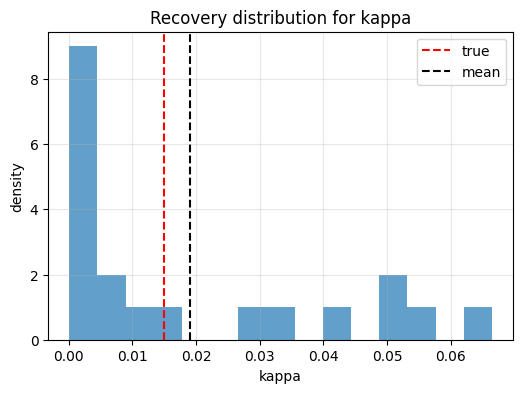

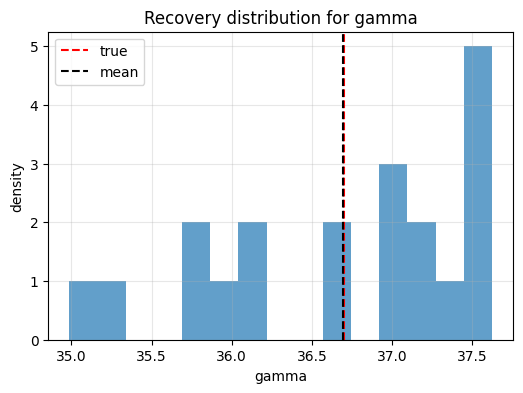

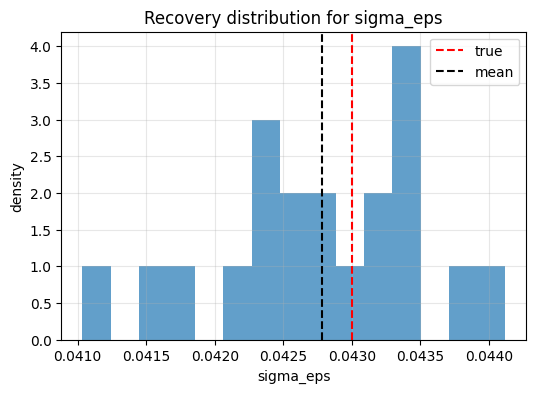

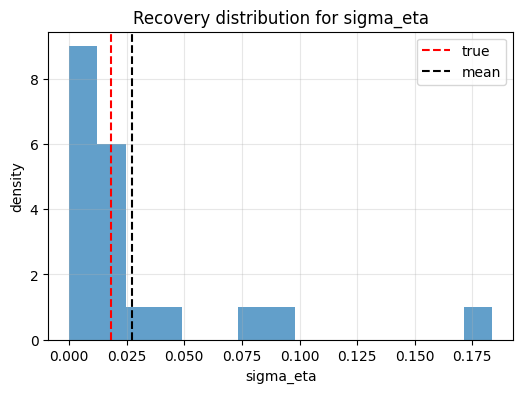

In [261]:
import matplotlib.pyplot as plt

def plot_parameter_densities_from_df(results, theta_true):
    param_names = ["kappa", "gamma", "sigma_eps", "sigma_eta"]

    for i, name in enumerate(param_names):
        values = results[f"{name}_hat"].to_numpy()

        plt.figure(figsize=(6, 4))
        plt.hist(values, bins=15, density=False, alpha=0.7)
        plt.axvline(theta_true[i], color="red", linestyle="--", label="true")
        plt.axvline(estimates.mean(axis=0)[i], color="black", linestyle="--", label="mean")
        plt.xlabel(name)
        plt.ylabel("density")
        plt.title(f"Recovery distribution for {name}")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.show()

plot_parameter_densities_from_df(results_optimal_20, theta_true)